In [43]:
from torch_geometric import datasets
import torch
import networkx as nx
import numpy as np
import shutil
import random
from math import ceil
from torch_geometric.utils import is_undirected, from_networkx, to_networkx

from rewiring.transform.AddRandomEdges import AddRandomEdges
from rewiring.transform.ReduceDiameter import ReduceDiameter

In [44]:
transform = ReduceDiameter(max_diam=3)

min_density = 0.5
transform = AddRandomEdges(min_density=min_density)

# shutil.rmtree('./../res/datasets/TUDataset/transformed/MUTAG/processed')

dset = datasets.TUDataset(root=f'./../res/datasets/TUDataset', 
                          name='MUTAG', 
                          use_node_attr=True, 
                          use_edge_attr=True).get(0)

G = to_networkx(dset).to_undirected()
G_prime = to_networkx(dset).to_undirected()
G_prime_c = nx.complement(G_prime)

num_edges = len(set(G_prime.edges))
num_nodes = len(list(G_prime.nodes))
max_possible_edges = (num_nodes * (num_nodes - 1)) / 2

num_edges_add = int(ceil(min_density * max_possible_edges) - num_edges)

if num_edges_add > 0:
    new_edges = random.sample(list(G_prime_c.edges), num_edges_add)
    for u, v in new_edges:
        G_prime.add_edge(u, v)
else:
    print("No rewiring done")

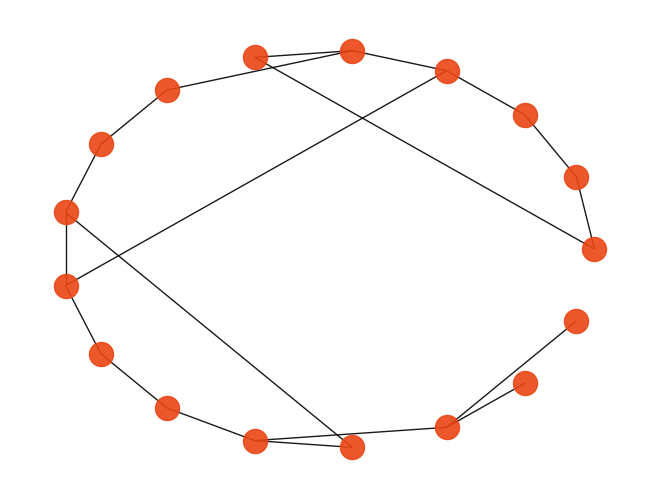

In [45]:
# so^>v<dph8

nx.draw_circular(G,
              node_color='#ea4615',
              node_shape='o',
              alpha=0.9,
              label='Example from MUTAG')

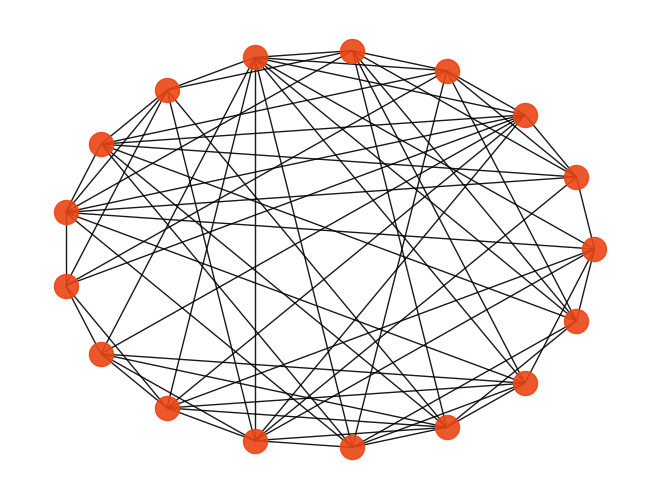

In [46]:
nx.draw_circular(G_prime,
              node_color='#ea4615',
              node_shape='o',
              alpha=0.9)